<a href="https://colab.research.google.com/github/Parth-22k/ML-Lab/blob/main/Exp6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


Accuracy without pruning: 98.55491329479769
Accuracy with pruning: 87.28323699421965
Confusion Matrix:
[[ 56   0  15   6]
 [  9   0   0   5]
 [  9   0 233   0]
 [  0   0   0  13]]
Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.73      0.74        77
           1       0.00      0.00      0.00        14
           2       0.94      0.96      0.95       242
           3       0.54      1.00      0.70        13

    accuracy                           0.87       346
   macro avg       0.56      0.67      0.60       346
weighted avg       0.85      0.87      0.86       346

Feature Importance:
buying : 0.10927967321995799
maint : 0.19619628743653095
doors : 0.0
persons : 0.24095055880857683
lug_boot : 0.05563167594044791
safety : 0.3979418045944863


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


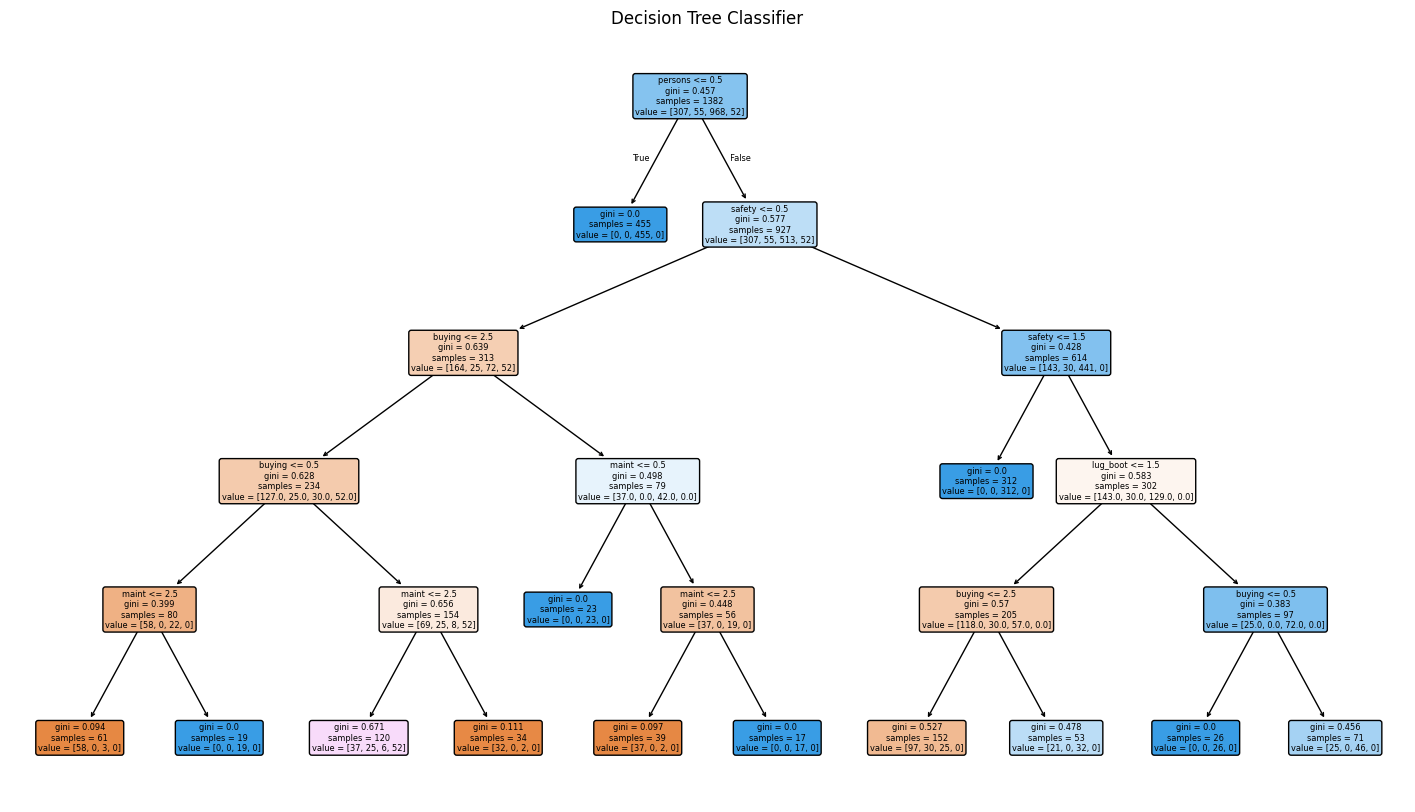

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, classification_report

# Load dataset
df = pd.read_csv('/content/drive/MyDrive/ML/car_evaluation_modified.csv')

# Encode categorical data
le = LabelEncoder()

for col in df.columns:
    df[col] = le.fit_transform(df[col])

# Separate input and target
X = df.drop('class', axis=1)
y = df['class']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20,
    random_state=42,
    stratify=y
)

# Decision Tree without pruning
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Accuracy
print("Accuracy without pruning:",
      accuracy_score(y_test, y_pred) * 100)

# Decision Tree with pruning
pruned_model = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=5,
    random_state=42
)

pruned_model.fit(X_train, y_train)

# Prediction
y_pred_pruned = pruned_model.predict(X_test)

print("Accuracy with pruning:",
      accuracy_score(y_test, y_pred_pruned) * 100)

# Confusion Matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_pruned))

# Classification Report
print("Classification Report:")
print(classification_report(y_test, y_pred_pruned))

# Feature Importance
print("Feature Importance:")
for feature, importance in zip(
        X.columns, pruned_model.feature_importances_):
    print(feature, ":", importance)

# Display tree
plt.figure(figsize=(18, 10))

plot_tree(
    pruned_model,
    feature_names=X.columns,
    filled=True,
    rounded=True
)

plt.title("Decision Tree Classifier")
plt.show()